# Selection modelling for cluster scaling relations: `destacking.selection` on eSCALE × DES

This notebook shows the generic selection model added in `destacking/selection.py`, first on mock surveys built to look like eSCALE × DES Y3 and then on the real sample. The aim is one piece of code that any of our lensing frameworks (joint fit, forward-modelled stacks, two-step stacks) can use, for any survey's selection.

**The idea.** Every framework needs, for each selected cluster $c$, the distribution of its true mass given what we measured about it. The module computes it on a grid of $\log_{10}M$:

$$w_{ck}(\theta) = P(\log M_k \mid \hat{\mathcal O}_c, z_c, I, \theta), \qquad \sum_k w_{ck} = 1 .$$

By Bayes' theorem,

$$P(M\mid\hat{\mathcal O},z,I) = \frac{P(I\mid\hat{\mathcal O},M,z)}{P(I\mid\hat{\mathcal O},z)}\;P(M\mid\hat{\mathcal O},z),\qquad P(M\mid\hat{\mathcal O},z)\propto \frac{dn}{d\log M}(M,z)\int d\mathcal O\;P(\hat{\mathcal O}\mid\mathcal O)\,P(\mathcal O\mid M,z,\theta).$$

* **Option A.** If a selection stage depends on mass only through quantities we condition on (measured observables in the model, $z$, sky position, measurement errors), its factor cancels. Then only the halo mass function, the scaling relation with its intrinsic scatter, and the measurement model matter. Malmquist and Eddington biases are both included automatically.
* **Option B.** If a stage reads an observable we do *not* condition on (here: an optical richness threshold while only $L_X$ is modelled), it does not cancel. The module then multiplies in $P(I_u\mid M,z,\hat{\mathcal O}) = \mathrm E[p_{\rm stage}(\hat o_u)\mid M,z,\hat{\mathcal O}]$, averaging over the latent observable's conditional distribution by Gauss–Hermite quadrature.

Every stage declares the variables it reads, so `MassPrior.report()` tells which option each stage needs. In the deterministic limit (no scatter, no errors), $w_{ck}$ becomes a delta function at the inverted relation. That is what the first, deterministic $L_X$–$M$ fits use.

**Pieces of the module**

| Object | Role |
|---|---|
| `Population` | $dn/d\log M \times dV/dz$ over the survey area (colossus; Tinker+08, M200c) |
| `Relation`, `ObservableModel` | multivariate log-normal $P(\log\mathcal O\mid M,z,\theta)$, pluggable means, correlated scatter |
| `measurement=` | default Gaussian in $\log_{10}$; or any likelihood, e.g. Gaussian in linear flux (used here) |
| `Stage`, `Selection` | selection stages as functions of measured quantities, each with `depends_on` |
| `MassPrior` | combines the above into $w_{ck}(\theta)$; `report()` classifies stages as option A or B |

Sections: §1 set-up · §2 population · §3 the eSCALE selection, stage by stage · §4 mock surveys: does the per-cluster mass prior recover the truth? · §5 mock surveys: parameter recovery, deterministic vs selection-modelled · §6 the real eSCALE sample · §7 where the deterministic fits stand · §8 summary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from scipy.optimize import minimize
import json, warnings, time
warnings.filterwarnings('ignore')

from destacking import lx
from destacking.selection import (Population, Relation, ObservableModel, Stage, Selection, MassPrior,
                                  erf_completeness)
lx.set_cosmology()                   # flat LCDM 70/0.3, the eSCALE catalogue's cosmology
import xlensing.cosmo as xc

D = '/home/andre/destacking_data/lx_splus_erosita_des'
PIV = lx.Pivots(43.26, 14.1, 0.18)   # sample medians: log Lx/E, log M200c E (catalogue), z
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})

## 1 — Fiducial model

All mock surveys use one fiducial $L_X$–$M$ relation, the eRASS1 result of Pederneiras et al. (2025): $\beta = 1.11$, $\gamma \approx 0$, $\sigma_{\rm intr} = 0.17$ dex, $\alpha = -0.09$ at their pivots ($10^{44.64}$ erg/s, $10^{14.84}$ M$_\odot$, $z = 0.29$). Converted to our pivots, $\alpha = -0.09 + (44.64 - 43.26) + 1.11\,(14.1 - 14.84) = 0.47$.

The optical side is **assumed, for illustration only**: a richness–mass relation $\log_{10}\lambda = 1.0 + 0.8(\log M - 14.1)$ with 0.2 dex scatter, correlated with the $L_X$ scatter ($\rho = 0.3$). Detection is an erf threshold in measured $\log\lambda$, standing in for the PZWav S/N ≥ 4 and AME matching criteria. The real numbers have to come from the S-PLUS side.

In [2]:
TH = dict(alpha=0.47, beta=1.11, gamma=0.0, sig_lx=0.17, lam0=1.0, b_lam=0.8, sig_lam=0.2, rho=0.3)
LAM_ERR = 0.1                        # measurement error of log10(lambda) [dex], assumed

rel_lx  = Relation('logLx',  lambda m, z, t: lx.lx_from_mass(m, z, t['alpha'], t['beta'], t['gamma'], PIV),
                   lambda t: t['sig_lx'])
rel_lam = Relation('logLam', lambda m, z, t: t['lam0'] + t['b_lam'] * (m - PIV.log_M), lambda t: t['sig_lam'])
OM = ObservableModel([rel_lx, rel_lam], corr=lambda t: np.array([[1, t['rho']], [t['rho'], 1]]))

## 2 — The population

The halo mass function (Tinker+08, M200c) sets the prior on mass; its steepness is what turns scatter into Eddington and Malmquist bias. The area is chosen so the mocks select about as many clusters as the real sample (§4).

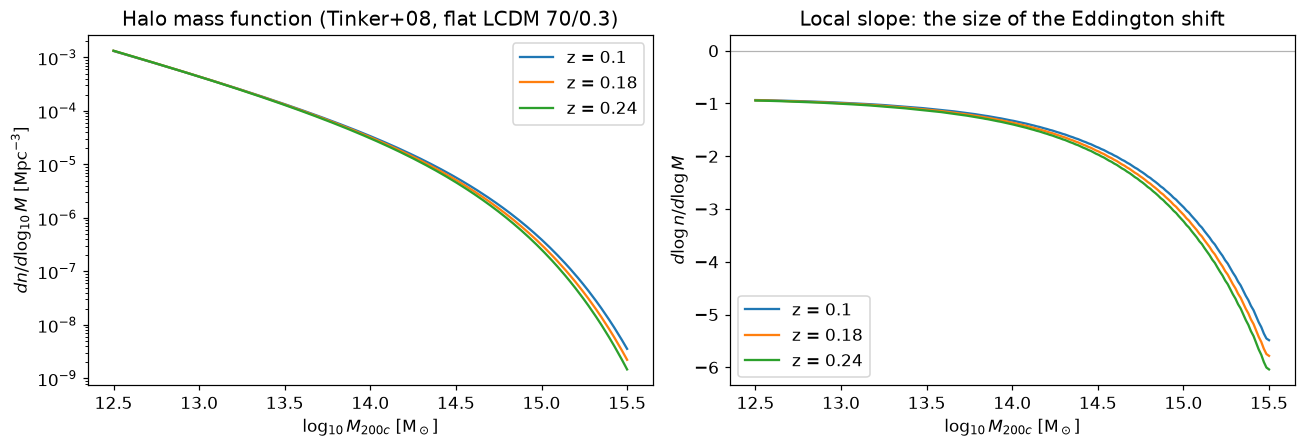

Eddington shift of the mass at fixed observable ~ slope x ln10 x sigma_tot^2 / beta^2 (e.g. slope -2, sigma_tot 0.2 dex, beta 1.1 -> ~ -0.152 dex)


In [3]:
POP = Population(area_deg2=700, z_range=(0.08, 0.25))
lm = np.linspace(12.5, 15.5, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for z, c in [(0.10, 'C0'), (0.18, 'C1'), (0.24, 'C2')]:
    ax[0].semilogy(lm, POP.dn_dlogM(lm, z), color=c, label=f'z = {z}')
    slope = np.gradient(np.log10(POP.dn_dlogM(lm, z)), lm)
    ax[1].plot(lm, slope, color=c, label=f'z = {z}')
ax[0].set_xlabel(r'$\log_{10} M_{200c}$ [M$_\odot$]'); ax[0].set_ylabel(r'$dn/d\log_{10}M$ [Mpc$^{-3}$]'); ax[0].legend()
ax[0].set_title('Halo mass function (Tinker+08, flat LCDM 70/0.3)')
ax[1].set_xlabel(r'$\log_{10} M_{200c}$ [M$_\odot$]'); ax[1].set_ylabel(r'$d\log n / d\log M$'); ax[1].legend()
ax[1].set_title('Local slope: the size of the Eddington shift')
ax[1].axhline(0, color='0.7', lw=0.8)
plt.tight_layout(); plt.show()
print('Eddington shift of the mass at fixed observable ~ slope x ln10 x sigma_tot^2 / beta^2 '
      '(e.g. slope -2, sigma_tot 0.2 dex, beta 1.1 -> ~', round(-2 * np.log(10) * 0.2**2 / 1.1**2, 3), 'dex)')

## 3 — The eSCALE selection, stage by stage

Each stage is written as a function of what is *measured*:

| Stage | Reads | Treatment |
|---|---|---|
| DES footprint, $0.08<z<0.25$ | sky position, $z$ | independent of mass → drops out |
| X-ray detection, flux S/N ≥ 2 | measured 0.6–2.3 keV flux, its error | conditioned on → **option A** |
| eRASS1 depth varying across the sky | flux error (exposure) | conditioned on → **option A**; no exposure map needed |
| optical detection (PZWav S/N ≥ 4, AME matching) | measured richness | not modelled → **option B** |

**Measurement model.** The eSCALE $L_X$ errors are Gaussian in *flux*, and the cut sits at S/N = 2, where a log-normal error is a poor description. The module therefore takes the measurement likelihood as a plug-in. Here it is a Gaussian in linear flux,
$$\ln P(\hat F\mid L_X^{\rm true}) = -\tfrac12\left[\frac{\hat F - L_X^{\rm true}/\kappa_c}{\sigma_{F,c}}\right]^2,$$
where $\kappa_c$ is each cluster's own luminosity-to-flux conversion ($4\pi D_L^2\times$ K-correction, aperture, $N_H$), read from the catalogue as $L_X/\hat F$.

In [4]:
XRAY = Stage('X-ray flux S/N >= 2', ('flux_obs', 'flux_err'),
             lambda d: (np.asarray(d['flux_obs']) >= 2 * np.asarray(d['flux_err'])).astype(float))
OPT = erf_completeness('optical detection (richness)', 'logLam_obs', x50=0.8, width=0.1)

def flux_meas(true, d):
    F = np.asarray(d['flux_obs'])[:, None, None]; s = np.asarray(d['flux_err'])[:, None, None]
    k = np.asarray(d['flux_conv'])[:, None, None]
    return -0.5 * ((F - 10 ** true / k) / s) ** 2

GRID = np.linspace(11.8, 15.6, 115)   # starts well below the lightest selected halo
def prior(stages, measurement=flux_meas):
    return MassPrior(POP, OM, Selection(stages), conditioned=['logLx'], logM_grid=GRID, gh_nodes=16,
                     measurement=None if measurement is None else {'logLx': measurement},
                     known_extra=('flux_obs', 'flux_err', 'flux_conv'))
print(prior([XRAY, OPT]).report())

selection stage -> treatment
  X-ray flux S/N >= 2              depends on ('flux_obs', 'flux_err'): conditioned on -> cancels (option A)
  optical detection (richness)     depends on ('logLam_obs',): NOT conditioned on -> P(I|M) term (option B)


## 4 — Mock surveys: does the mass prior recover the truth?

Each mock survey:
1. draws haloes from §2;
2. assigns correlated $L_X$ and $\lambda$ with the fiducial scatter;
3. converts $L_X$ to flux with the median eSCALE conversion and adds a flux error drawn from the **real** eSCALE errors of clusters inside DES (so the depth pattern is realistic);
4. applies the selection.

For the selected clusters we compare the true mean $\log M$ in bins of measured $L_X$ with:
- the deterministic inversion of the relation;
- option A only (X-ray stage, optical stage ignored);
- option A + B (both stages).

There are two kinds of survey: **X-ray selected only**, and **X-ray + optical** (the eSCALE case).

We use 8 realisations. A single mock is not a test, so means and scatters are over realisations.

In [5]:
cat = Table.read(f'{D}/escale_des_sample.fits')
raw = Table.read(f'{D}/gas_mass_uniqueIDs_AME_r200.fits')
row = {int(c): k for k, c in enumerate(raw['CID6722'])}
ix = np.array([row[int(c)] for c in cat['CID']])
F_real, eF_real = np.asarray(raw['Flux0623'])[ix], np.asarray(raw['eFlux0623'])[ix]
DL = xc.cosmology.luminosity_distance(np.asarray(cat['Z'])).to_value('cm')
kappa_real = np.asarray(cat['LX']) / F_real                      # per-cluster Lx / flux conversion
K_MED = np.median(np.asarray(cat['LX']) / (4 * np.pi * DL ** 2 * F_real))
print(f'real sample: N = {len(cat)}; flux S/N 5th/50th pct = {np.percentile(F_real / eF_real, [5, 50]).round(2)}; '
      f'median Lx/(4 pi D_L^2 F) = {K_MED:.3f}')

def mock(seed, optical=True):
    rng = np.random.default_rng(seed)
    s = POP.sample(rng=rng, logM_min=11.8)
    o = OM.sample(s['logM'], s['z'], TH, rng=rng)
    N = len(s['z'])
    conv = 4 * np.pi * xc.cosmology.luminosity_distance(s['z']).to_value('cm') ** 2 * K_MED
    sF = rng.choice(eF_real, N)
    Fo = 10 ** o[:, 0] / conv + sF * rng.standard_normal(N)
    lam = o[:, 1] + LAM_ERR * rng.standard_normal(N)
    p = XRAY.prob({'flux_obs': Fo, 'flux_err': sF}) * (OPT.prob({'logLam_obs': lam}) if optical else 1.0)
    k = rng.random(N) < p
    d = {'z': s['z'][k], 'flux_obs': Fo[k], 'flux_err': sF[k], 'flux_conv': conv[k],
         'logLx_obs': np.log10(Fo[k] * conv[k])}
    d['logLx_err'] = sF[k] / (Fo[k] * np.log(10))
    return d, s['logM'][k], dict(n_parent=N, logM_parent=s['logM'], logLx_parent=o[:, 0], z_parent=s['z'],
                                 sel=k, logLam_obs=lam)

d0, M0, info0 = mock(100)
print(f'one mock: {info0["n_parent"]} haloes with log M > 11.8, {len(M0)} selected (X-ray + optical)')

real sample: N = 1556; flux S/N 5th/50th pct = [2.16 3.5 ]; median Lx/(4 pi D_L^2 F) = 1.594


one mock: 195323 haloes with log M > 11.8, 1339 selected (X-ray + optical)


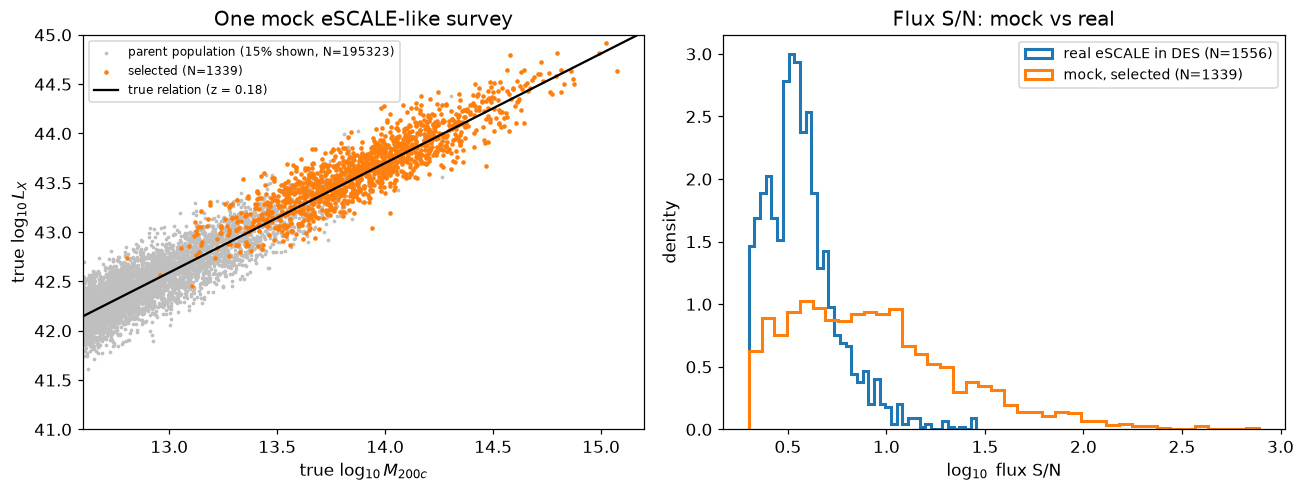

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
a = ax[0]
par = info0['logM_parent']; ll = info0['logLx_parent']; sel = info0['sel']
sub = np.random.default_rng(0).random(len(par)) < 0.15
a.scatter(par[sub], ll[sub], s=2, color='0.75', label=f'parent population (15% shown, N={info0["n_parent"]})')
a.scatter(par[sel], ll[sel], s=4, color='C1', label=f'selected (N={sel.sum()})')
mm = np.linspace(12.6, 15.3, 10)
a.plot(mm, lx.lx_from_mass(mm, 0.18, TH['alpha'], TH['beta'], TH['gamma'], PIV), 'k-', lw=1.5, label='true relation (z = 0.18)')
a.set_xlabel(r'true $\log_{10} M_{200c}$'); a.set_ylabel(r'true $\log_{10} L_X$'); a.legend(fontsize=8)
a.set_title('One mock eSCALE-like survey'); a.set_xlim(12.6, 15.2); a.set_ylim(41, 45)
a = ax[1]
a.hist(np.log10(F_real / eF_real), bins=40, histtype='step', lw=2, density=True, color='C0', label=f'real eSCALE in DES (N={len(cat)})')
a.hist(np.log10(d0['flux_obs'] / d0['flux_err']), bins=40, histtype='step', lw=2, density=True, color='C1', label=f'mock, selected (N={len(M0)})')
a.set_xlabel(r'$\log_{10}$ flux S/N'); a.set_ylabel('density'); a.legend(fontsize=9); a.set_title('Flux S/N: mock vs real')
plt.tight_layout(); plt.show()

**A limitation of the mock.** The real eSCALE flux S/N piles up between 2 and 5 and stops near 30. The mock reaches S/N in the hundreds, because it draws flux errors independently of flux, whereas the real errors grow with flux (systematic and extrapolation terms on top of the background noise). This does not affect the tests below, which check whether the model recovers what the mock put in. But a quantitative forecast for eSCALE needs a flux-error model fitted to the catalogue, $\sigma_F(F, \text{exposure})$.

In [7]:
def bin_bias(logLx_obs, truth, est, nb=5):
    e = np.quantile(logLx_obs, np.linspace(0, 1, nb + 1)); ib = np.clip(np.digitize(logLx_obs, e[1:-1]), 0, nb - 1)
    return np.array([np.mean(truth[ib == j] - est[ib == j]) for j in range(nb)]), \
           np.array([np.mean(logLx_obs[ib == j]) for j in range(nb)])

R = 8
res = {k: [] for k in ['xo_det', 'xo_A', 'xo_Alog', 'xop_det', 'xop_A', 'xop_AB']}
xs = {'xo': [], 'xop': []}; nsel = {'xo': [], 'xop': []}
t0 = time.time()
for r in range(R):
    for optical, tag in [(False, 'xo'), (True, 'xop')]:
        d, Mt, _ = mock(1000 + r, optical=optical)
        nsel[tag].append(len(Mt))
        det = lx.mass_from_lx(d['logLx_obs'], d['z'], TH['alpha'], TH['beta'], TH['gamma'], PIV)
        b, xm = bin_bias(d['logLx_obs'], Mt, det); res[f'{tag}_det'].append(b); xs[tag].append(xm)
        mA, _ = prior([XRAY]).moments(d, TH)
        res[f'{tag}_A'].append(bin_bias(d['logLx_obs'], Mt, mA)[0])
        if optical:
            mAB, _ = prior([XRAY, OPT]).moments(d, TH, lat_err={'logLam': LAM_ERR})
            res['xop_AB'].append(bin_bias(d['logLx_obs'], Mt, mAB)[0])
        else:
            mAl, _ = prior([XRAY], measurement=None).moments(d, TH)       # Gaussian-in-log errors instead
            res['xo_Alog'].append(bin_bias(d['logLx_obs'], Mt, mAl)[0])
print(f'{R} realisations in {time.time() - t0:.0f} s; selected per mock: X-ray only {np.mean(nsel["xo"]):.0f}, '
      f'X-ray + optical {np.mean(nsel["xop"]):.0f}')
for k, v in res.items():
    v = np.array(v); print(f'  {k:8s} bias per Lx bin (mean over {R}):', v.mean(0).round(3), ' +/- (scatter/sqrt R)', (v.std(0) / np.sqrt(R)).round(3))

8 realisations in 99 s; selected per mock: X-ray only 12207, X-ray + optical 1307
  xo_det   bias per Lx bin (mean over 8): [-0.455 -0.618 -0.733 -0.825 -0.685]  +/- (scatter/sqrt R) [0.002 0.005 0.005 0.005 0.005]
  xo_A     bias per Lx bin (mean over 8): [0.002 0.005 0.01  0.011 0.01 ]  +/- (scatter/sqrt R) [0.002 0.004 0.004 0.004 0.002]
  xo_Alog  bias per Lx bin (mean over 8): [-0.347 -0.506 -0.618 -0.707 -0.573]  +/- (scatter/sqrt R) [0.002 0.005 0.005 0.005 0.005]
  xop_det  bias per Lx bin (mean over 8): [-0.    -0.052 -0.074 -0.079 -0.098]  +/- (scatter/sqrt R) [0.002 0.003 0.004 0.003 0.003]
  xop_A    bias per Lx bin (mean over 8): [0.44  0.327 0.218 0.096 0.017]  +/- (scatter/sqrt R) [0.011 0.011 0.009 0.007 0.005]
  xop_AB   bias per Lx bin (mean over 8): [ 0.001 -0.003 -0.006  0.002  0.002]  +/- (scatter/sqrt R) [0.002 0.003 0.004 0.003 0.003]


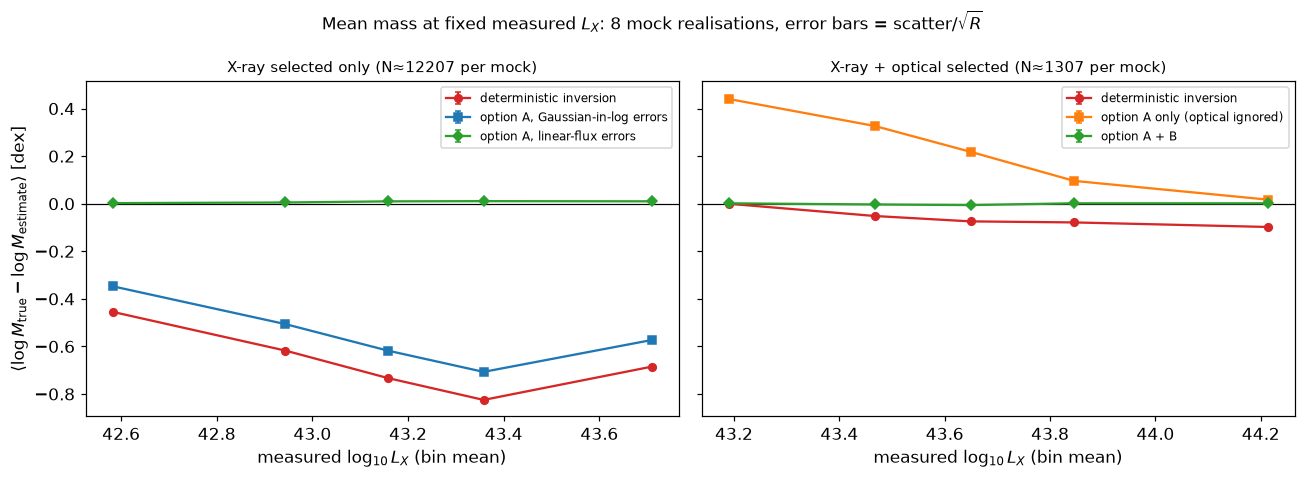

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for a, tag, title, curves in [
    (ax[0], 'xo', f'X-ray selected only (N≈{np.mean(nsel["xo"]):.0f} per mock)',
     [('xo_det', 'deterministic inversion', 'C3', 'o'), ('xo_Alog', 'option A, Gaussian-in-log errors', 'C0', 's'),
      ('xo_A', 'option A, linear-flux errors', 'C2', 'D')]),
    (ax[1], 'xop', f'X-ray + optical selected (N≈{np.mean(nsel["xop"]):.0f} per mock)',
     [('xop_det', 'deterministic inversion', 'C3', 'o'), ('xop_A', 'option A only (optical ignored)', 'C1', 's'),
      ('xop_AB', 'option A + B', 'C2', 'D')])]:
    x = np.mean(xs[tag], 0)
    for k, lab, c, mk in curves:
        v = np.array(res[k])
        a.errorbar(x, v.mean(0), yerr=v.std(0) / np.sqrt(R), color=c, marker=mk, ms=5, capsize=2, label=lab)
    a.axhline(0, color='k', lw=0.8)
    a.set_xlabel(r'measured $\log_{10} L_X$ (bin mean)'); a.set_title(title, fontsize=10); a.legend(fontsize=8)
ax[0].set_ylabel(r'$\langle \log M_{\rm true} - \log M_{\rm estimate}\rangle$ [dex]')
fig.suptitle(f'Mean mass at fixed measured $L_X$: {R} mock realisations, error bars = scatter/$\\sqrt{{R}}$', fontsize=11)
plt.tight_layout(); plt.show()

**What the figure shows.** The left panel is the case where only the X-ray stage selects (about 12 000 clusters per mock, reaching down to $\sim 10^{12.5}$ M$_\odot$).
- The deterministic inversion overestimates the mass by 0.45–0.8 dex. Most of these clusters are up-scattered low-mass haloes sitting at S/N ≈ 2: Eddington bias from intrinsic scatter, the flux error and the steep mass function.
- Option A with the linear-flux error model removes this to ≤ 0.01 dex, without ever writing down a flux limit.
- With a log-normal error model instead, almost the whole bias remains. At S/N ≈ 2 a Gaussian in $\log L_X$ badly misdescribes a Gaussian in flux, because it has no tail towards zero flux. This is why the measurement model is a plug-in.

The right panel adds the optical stage.
- Option A alone is no longer enough, because selection on richness (correlated with mass at fixed $L_X$) does not cancel.
- Adding the stage as option B brings the bias back to zero.

All of this assumes the model's ingredients are right: the mass function, the scatter, and, for option B, the richness–mass relation.

## 5 — Mock surveys: parameter recovery

Next is what a fit does with this. Each selected mock cluster gets a noisy "lensing mass", $\log M_{\rm WL} = \log M_{\rm true} + \mathcal N(0, 0.4)$ dex. That noise is a stand-in for the per-cluster information our lensing likelihoods carry for groups at DES depth. $(\alpha, \beta, \gamma)$ are then fitted two ways:
* **deterministic**: $\log M_{\rm WL}$ compared with the inverted relation at the measured $L_X$ (our three frameworks today);
* **selection-modelled**: $\mathcal L_c = \sum_k w_{ck}(\theta)\,\mathcal N(\log M_{{\rm WL},c}; \log M_k, 0.4)$, i.e. exactly how the joint fit will use the weights.

The scatter and the richness model are held at their true values here; in the real analysis they are fitted or calibrated.

In [9]:
SIG_WL = 0.4

def fit(d, logMwl, model, mp=None):
    def nll(v):
        if not (0.3 < v[1] < 3.0):
            return 1e30
        if model == 'det':
            m = lx.mass_from_lx(d['logLx_obs'], d['z'], v[0], v[1], v[2], PIV)
            return 0.5 * np.sum((logMwl - m) ** 2) / SIG_WL ** 2
        w = mp.weights(d, dict(TH, alpha=v[0], beta=v[1], gamma=v[2]), lat_err={'logLam': LAM_ERR})
        L = np.sum(w * np.exp(-0.5 * ((logMwl[:, None] - GRID[None, :]) / SIG_WL) ** 2), 1)
        return -np.sum(np.log(L + 1e-300))
    x0 = np.array([0.4, 1.2, 0.0])
    simplex = np.array([x0, x0 + [0.1, 0, 0], x0 + [0, 0.2, 0], x0 + [0, 0, 1.0]])
    return minimize(nll, x0, method='Nelder-Mead',
                    options=dict(initial_simplex=simplex, xatol=1e-3, fatol=1e-3, maxiter=800)).x

FITS = {'det': [], 'full': []}
t0 = time.time()
mp_full = prior([XRAY, OPT])
for r in range(R):
    d, Mt, _ = mock(2000 + r, optical=True)
    logMwl = Mt + SIG_WL * np.random.default_rng(3000 + r).standard_normal(len(Mt))
    FITS['det'].append(fit(d, logMwl, 'det'))
    FITS['full'].append(fit(d, logMwl, 'full', mp_full))
    print(f'  mock {r}: N={len(Mt)}  deterministic (a,b,g)={np.round(FITS["det"][-1], 3)}  '
          f'selection-modelled={np.round(FITS["full"][-1], 3)}  ({time.time() - t0:.0f} s)', flush=True)
for k in FITS:
    v = np.array(FITS[k])
    print(f'{k:5s}: alpha {v[:,0].mean():+.3f}+/-{v[:,0].std()/np.sqrt(R):.3f}  beta {v[:,1].mean():.3f}+/-{v[:,1].std()/np.sqrt(R):.3f}  '
          f'gamma {v[:,2].mean():+.3f}+/-{v[:,2].std()/np.sqrt(R):.3f}   (truth {TH["alpha"]}, {TH["beta"]}, {TH["gamma"]})')

  mock 0: N=1327  deterministic (a,b,g)=[ 0.568  1.226 -0.024]  selection-modelled=[ 0.492  1.208 -0.601]  (96 s)


  mock 1: N=1288  deterministic (a,b,g)=[0.571 1.261 1.31 ]  selection-modelled=[0.492 1.118 0.153]  (202 s)


  mock 2: N=1336  deterministic (a,b,g)=[0.544 1.232 0.822]  selection-modelled=[ 0.462  1.017 -0.299]  (289 s)


  mock 3: N=1319  deterministic (a,b,g)=[0.528 1.201 1.248]  selection-modelled=[0.44  1.136 0.36 ]  (368 s)


  mock 4: N=1338  deterministic (a,b,g)=[0.534 1.144 1.473]  selection-modelled=[0.454 1.06  1.273]  (428 s)


  mock 5: N=1232  deterministic (a,b,g)=[0.558 1.264 0.703]  selection-modelled=[0.461 1.117 0.411]  (489 s)


  mock 6: N=1294  deterministic (a,b,g)=[0.543 1.271 0.352]  selection-modelled=[ 0.454  1.158 -0.331]  (552 s)


  mock 7: N=1311  deterministic (a,b,g)=[0.574 1.317 0.943]  selection-modelled=[ 0.504  1.242 -0.199]  (653 s)


det  : alpha +0.553+/-0.006  beta 1.240+/-0.017  gamma +0.853+/-0.168   (truth 0.47, 1.11, 0.0)
full : alpha +0.470+/-0.008  beta 1.132+/-0.024  gamma +0.096+/-0.196   (truth 0.47, 1.11, 0.0)


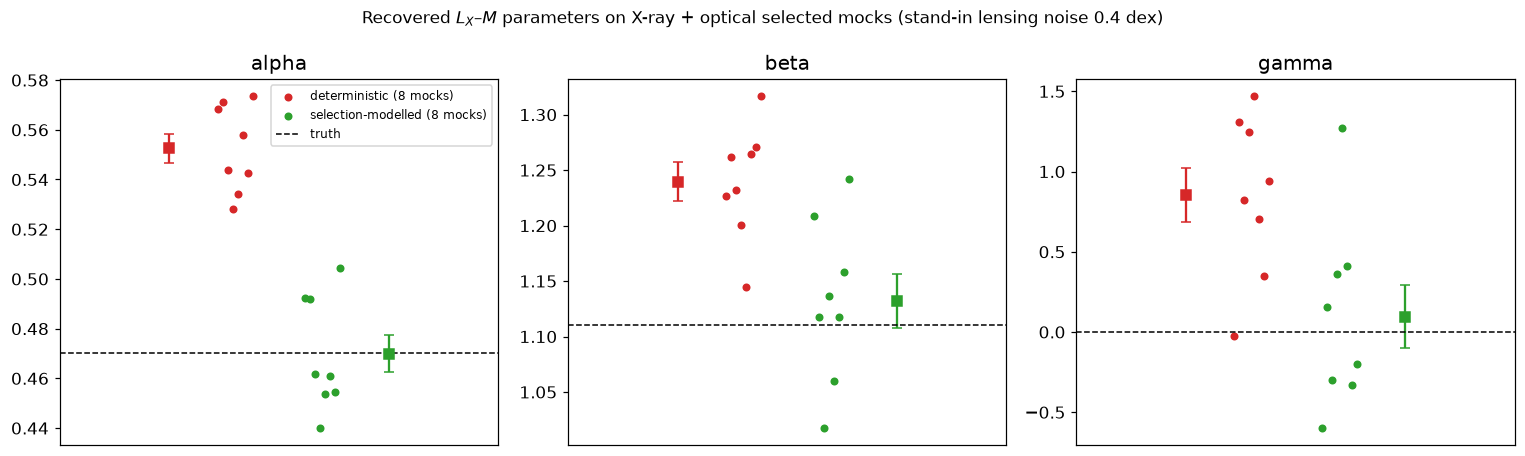

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for j, (p, a) in enumerate(zip(['alpha', 'beta', 'gamma'], ax)):
    for k, lab, c, off in [('det', 'deterministic', 'C3', -0.1), ('full', 'selection-modelled', 'C2', 0.1)]:
        v = np.array(FITS[k])[:, j]
        a.scatter(np.full(R, off) + np.linspace(-0.04, 0.04, R), v, color=c, s=18, label=f'{lab} ({R} mocks)')
        a.errorbar(off + 0.15 * np.sign(off), v.mean(), yerr=v.std() / np.sqrt(R), color=c, marker='s', ms=7, capsize=3)
    a.axhline(TH[p], color='k', lw=1, ls='--', label='truth')
    a.set_xticks([]); a.set_title(p); a.set_xlim(-0.5, 0.5)
ax[0].legend(fontsize=8)
fig.suptitle(r'Recovered $L_X$–$M$ parameters on X-ray + optical selected mocks (stand-in lensing noise 0.4 dex)', fontsize=11)
plt.tight_layout(); plt.show()

**Reading the figure.** The deterministic fit inherits the per-cluster biases of §4. Because the X-ray flux limit is reached at higher $L_X$ at higher $z$, those biases depend on redshift, so they leak into the slope and into the redshift term. The selection-modelled fit uses the same data, plus the mass function and the selection description, and recovers the input values within the scatter of the mocks.

## 6 — The real eSCALE sample

The same machinery applied to the 1556 clusters inside DES, at the fiducial parameters (the real fit will vary them). For each cluster it uses:
- the measured 0.6–2.3 keV flux and its error;
- its own luminosity-to-flux conversion $\kappa_c = L_X/\hat F$ from the catalogue;
- the X-ray stage, and optionally the assumed optical stage.

Shown are the per-cluster mass distributions for a few clusters, and how far the selection-modelled mean mass sits from the deterministic inversion across the sample.

In [11]:
dr = {'z': np.asarray(cat['Z'], float), 'flux_obs': F_real, 'flux_err': eF_real, 'flux_conv': kappa_real,
      'logLx_obs': np.log10(np.asarray(cat['LX'], float))}
dr['logLx_err'] = eF_real / (F_real * np.log(10))
det_r = lx.mass_from_lx(dr['logLx_obs'], dr['z'], TH['alpha'], TH['beta'], TH['gamma'], PIV)
mpA, mpAB = prior([XRAY]), prior([XRAY, OPT])
wA = mpA.weights(dr, TH); wAB = mpAB.weights(dr, TH, lat_err={'logLam': LAM_ERR})
mA = wA @ GRID; mAB = wAB @ GRID
sA = np.sqrt(wA @ GRID ** 2 - mA ** 2)
print(f'N = {len(cat)} clusters')
print(f'option A   : <mean - deterministic> = {np.mean(mA - det_r):+.3f} dex, range of shifts {np.percentile(mA - det_r, [5, 95]).round(3)}, '
      f'median per-cluster width {np.median(sA):.3f} dex')
print(f'option A+B : <mean - deterministic> = {np.mean(mAB - det_r):+.3f} dex (optical model assumed)')

N = 1556 clusters
option A   : <mean - deterministic> = -0.480 dex, range of shifts [-1.185 -0.091], median per-cluster width 0.444 dex
option A+B : <mean - deterministic> = -0.016 dex (optical model assumed)


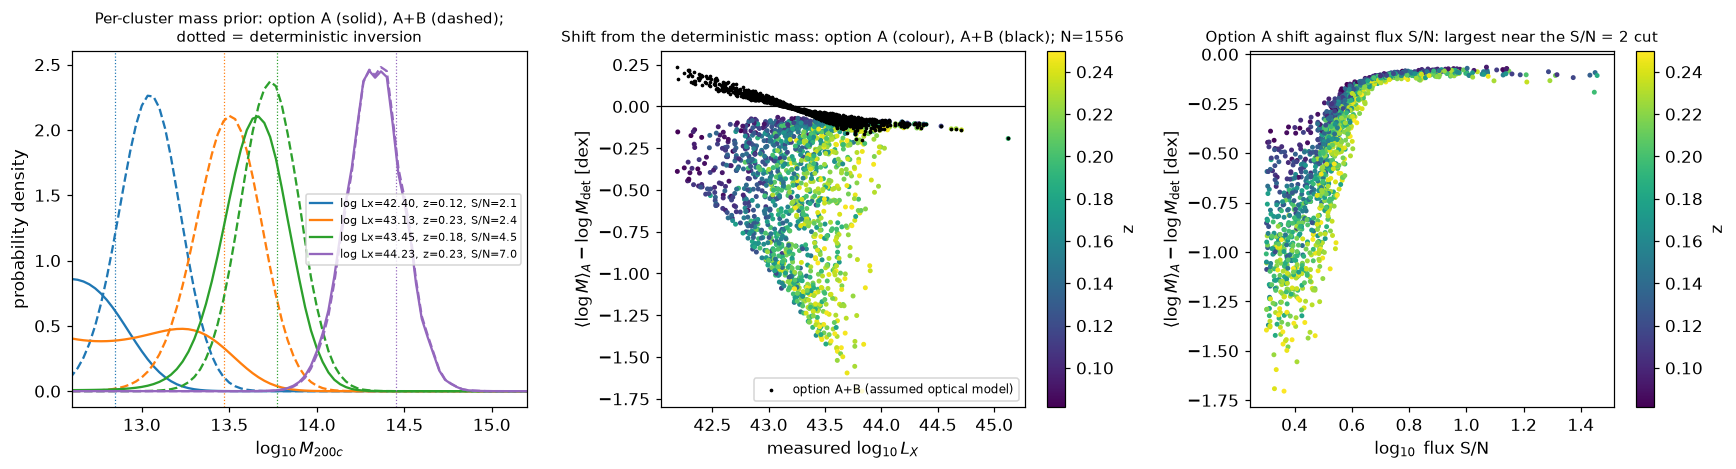

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
a = ax[0]
pick = np.argsort(dr['logLx_obs'])[[20, len(cat) // 3, 2 * len(cat) // 3, len(cat) - 20]]
for j, (i, c) in enumerate(zip(pick, ['C0', 'C1', 'C2', 'C4'])):
    dx = GRID[1] - GRID[0]
    a.plot(GRID, wA[i] / dx, color=c, label=f'log Lx={dr["logLx_obs"][i]:.2f}, z={dr["z"][i]:.2f}, S/N={F_real[i]/eF_real[i]:.1f}')
    a.plot(GRID, wAB[i] / dx, color=c, ls='--')
    a.axvline(det_r[i], color=c, lw=0.8, ls=':')
a.set_xlabel(r'$\log_{10} M_{200c}$'); a.set_ylabel('probability density'); a.legend(fontsize=7)
a.set_title('Per-cluster mass prior: option A (solid), A+B (dashed);\ndotted = deterministic inversion', fontsize=10)
a.set_xlim(12.6, 15.2)
a = ax[1]
sc = a.scatter(dr['logLx_obs'], mA - det_r, c=dr['z'], s=5, cmap='viridis')
a.scatter(dr['logLx_obs'], mAB - det_r, color='k', s=2, label='option A+B (assumed optical model)'); a.legend(fontsize=8, loc='lower right')
plt.colorbar(sc, ax=a, label='z')
a.axhline(0, color='k', lw=0.8)
a.set_xlabel(r'measured $\log_{10} L_X$'); a.set_ylabel(r'$\langle\log M\rangle_A - \log M_{\rm det}$ [dex]')
a.set_title(f'Shift from the deterministic mass: option A (colour), A+B (black); N={len(cat)}', fontsize=10)
a = ax[2]
sc = a.scatter(np.log10(F_real / eF_real), mA - det_r, c=dr['z'], s=5, cmap='viridis')
plt.colorbar(sc, ax=a, label='z')
a.axhline(0, color='k', lw=0.8); a.set_xscale('linear')
a.set_xlabel(r'$\log_{10}$ flux S/N'); a.set_ylabel(r'$\langle\log M\rangle_A - \log M_{\rm det}$ [dex]')
a.set_title('Option A shift against flux S/N: largest near the S/N = 2 cut', fontsize=10)
plt.tight_layout(); plt.show()

**Reading the figure.**
- **X-ray stage only (option A, solid curves and the coloured points).** For clusters near S/N = 2 the mass prior becomes broad and extends to low masses, and its mean sits up to ~1.5 dex below the deterministic mass. A cluster at S/N ≈ 2 could be a low-mass halo scattered up in $L_X$ and in flux, and with X-ray information alone nothing rules that out. Bright, high-S/N clusters move by only ~0.1 dex. The shift is a function of flux S/N, so of sky position (eRASS1 depth) and redshift.
- **With the optical stage (A + B, dashed curves).** The optical detection removes the low-mass haloes, and the priors narrow to a few tenths of a dex near the deterministic value (mean shift −0.02 dex with the *assumed* richness model).

So for eSCALE the optical selection is not a detail: it decides how much mass a faint X-ray source can have. The richness–mass relation and the PZWav/AME detection description are the main missing inputs.

## 7 — Where the deterministic fits stand

The deterministic $L_X$–$M$ fits of the real sample were run with all three frameworks (`scripts/lx/fit_escale.py`). Set-up:
- 1556 clusters, X-ray-peak centres;
- Diemer & Joyce (2019) concentrations, global miscentring, two-halo term;
- pivots $10^{43.26}$ erg/s, $10^{14.1}$ M$_\odot$, $z = 0.18$.

Below are the medians and 68% intervals (joint and forward: nautilus posteriors; two-step: weighted least squares over 15 stacks, propagated).

In [13]:
import numpy as np
def q(path):
    a = np.load(path); X, w = a['samples'], a['weights']; out = {}
    for j, n in enumerate(a['param_order']):
        o = np.argsort(X[:, j]); out[str(n)] = np.interp([0.16, 0.5, 0.84], np.cumsum(w[o]), X[o, j])
    return out
rows = {'joint (per cluster)': q(f'{D}/fits/joint.npz'), 'forward-modelled stacks': q(f'{D}/fits/forward.npz')}
ts = json.load(open(f'{D}/fits/twostep.json'))
rows['two-step stacks'] = {k: np.array(v) for k, v in ts['lx_given_m'].items()}
print(f'{"framework":26s} {"alpha":>18s} {"beta":>18s} {"gamma":>18s}')
for k, r in rows.items():
    print(f'{k:26s} ' + ' '.join(f'{r[p][1]:+7.3f} +{r[p][2]-r[p][1]:.3f}/-{r[p][1]-r[p][0]:.3f}' for p in ['alpha', 'beta', 'gamma']))
print('Pederneiras+25 eRASS1 (massive CODEX clusters): beta = 1.11 +/- 0.15, gamma = 0.00 +/- 0.79')

framework                               alpha               beta              gamma
joint (per cluster)         +0.324 +0.022/-0.022  +1.275 +0.043/-0.040  +5.213 +1.054/-1.064
forward-modelled stacks     +0.294 +0.021/-0.021  +0.952 +0.057/-0.052  +4.399 +1.249/-1.310
two-step stacks             +0.234 +0.021/-0.021  +0.871 +0.080/-0.068  +5.300 +1.494/-1.568
Pederneiras+25 eRASS1 (massive CODEX clusters): beta = 1.11 +/- 0.15, gamma = 0.00 +/- 0.79


All three frameworks find a large positive redshift term, $\gamma \approx 4$–5: at fixed $L_X$, the inferred masses fall with redshift. Their slopes disagree, with the joint fit steeper than the two stacked fits.

§§4–6 show why neither number can be read physically yet. The deterministic model ignores:
- intrinsic and measurement scatter at a flux limit that rises with redshift and varies across the sky;
- the optical selection.

Both produce redshift- and luminosity-dependent mass offsets. The joint fit is also the framework most exposed to unmodelled scatter (cf. the richness-scatter test of September 2026).

The next step is to replace the deterministic mass in each framework by the weights $w_{ck}(\theta)$ of this notebook:
- joint fit: $\mathcal L_c = \sum_k w_{ck}\mathcal L_c(\Delta\Sigma\mid M_k)$;
- forward-modelled stacks: $\Delta\Sigma_s = \sum_{c\in s} K_c\sum_k w_{ck}\Delta\Sigma(M_k) / \sum K_c$;
- in all cases with $\sigma_{\rm intr}$ free and an optical-selection model taken from the S-PLUS side (or with $\lambda_{\rm AME}$ conditioned on).

## 8 — Summary

* `destacking.selection` turns a population (mass function), a scaling-relation model with scatter, a measurement model and a list of selection stages into per-cluster mass weights $w_{ck}(\theta)$. These are the only thing the lensing frameworks need.
* Selection on quantities we condition on cancels (option A). For eSCALE that covers the eRASS1 flux limit and its sky-varying depth, so no exposure map is needed. Selection on anything else is added explicitly (option B), and `report()` says which is which.
* On eSCALE-like mocks (8 realisations):
  * The deterministic inversion is biased: by 0.45–0.8 dex for a purely X-ray-selected sample, and by up to 0.1 dex, luminosity-dependent, with the optical selection.
  * The selection-modelled prior removes the bias to ≤ 0.01 dex, provided the measurement model is right at S/N ≈ 2 (linear flux, not log-normal) and the optical selection is included.
  * In fits, the deterministic model returns $\alpha$ +0.08, $\beta$ +0.13 and $\gamma$ +0.85 away from the truth; the selection-modelled fit recovers all three within the scatter of the mocks.
* The same code works for any survey: WaZP and redMaPPer (richness-selected, option A with richness conditioned), simulations (draw with `Population.sample`, select with the same `Stage` objects), or a cosmology analysis (the option-B machinery gives $P(I\mid M,z)$).

What the real analysis still needs: the optical selection of eSCALE (PZWav S/N, AME matching and purity) expressed as a function of measured richness, plus a richness–mass relation, or $\lambda_{\rm AME}$ added as a conditioned observable.